Site-https://cordis.europa.eu/project/id/211743/reporting

## Pendulum


optimal diameter to nullify thermal Noise =  0.01574362342639447
Dilution Factor 4.851075080519808
Resonant angular frequency ω₀ = 2.8591956910991594 rad/s
Resonant frequency f₀ = 0.4550551275054791 Hz
Thermal loss matrix =  [2.80640294e-47 2.80695229e-47 2.80750175e-47 ... 1.40597452e-45
 1.40624974e-45 1.40652500e-45]
Bulk loss matrix =  1e-09
[1.e-09 1.e-09 1.e-09 ... 1.e-09 1.e-09 1.e-09]
Surface Loss matrix =  [1.33333333e-09 1.33333333e-09 1.33333333e-09 ... 1.33333333e-09
 1.33333333e-09 1.33333333e-09]
Total loss =  [4.80993037e-10 4.80993037e-10 4.80993037e-10 ... 4.80993037e-10
 4.80993037e-10 4.80993037e-10]


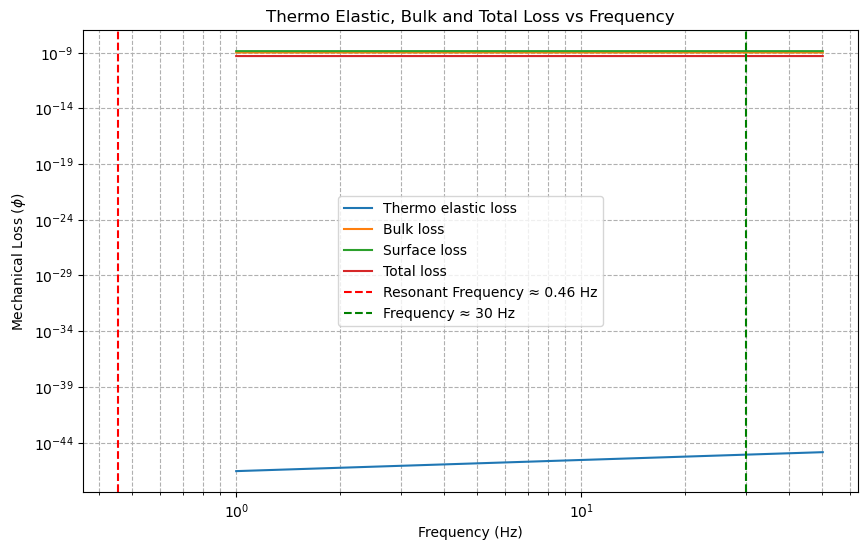

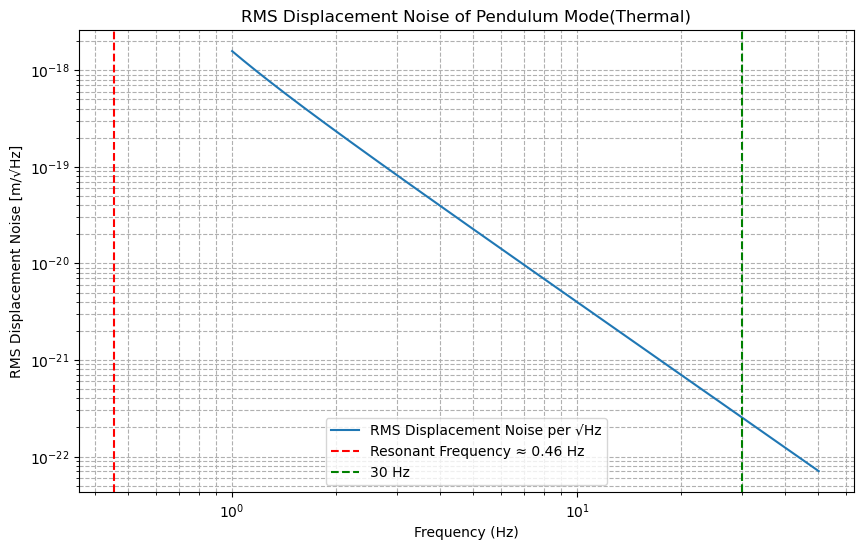

Resonant angular frequency ω₀ = 2.8591956910991594 rad/s
Resonant frequency f₀ = 0.4550551275054791 Hz


In [19]:
#length 10 km
import numpy as np
import matplotlib.pyplot as plt

# Physical constants
k_B = 1.380649e-23 #m^2 kg s^-2 K^-1
T = 15 #K(ET-LF)   
m = 211#mass(ET-LF)-https://indico.ego-gw.it/event/217/contributions/2539/attachments/1512/2658/2021_08_31_G2net.pdf            
g = 9.81 #m/s^2         
l = 1.2 #m(ET-LF)
Y = 1.68e11 #(N/m²)/Pa--https://www.universitywafer.com/mechanical-properties-monocrystalline-silicon.html?srsltid=AfmBOoprx3Ey7HPRuowuFE7JYDXCqyotTfsPxokJrIiFCvVXIrT80y4H
rho=2330 #density(ET_LF)
C=20#specific heat(ET-LF)-Google search
alpha=-0.5e-9 #coefficient of thermal expansion(ET-LF)
d=3e-3 #diameter of the fiber(ET-LF)
C2=1.22e-11
hphi_s = 5e-13 #product of the mechanical loss of the material surface, φs and the depth ,h-google search
beta=-7.9e-6 #ET-LF
#Kappa=1.49 #W/mK (thermal Conductivity)(ET-LF)-https://www.universitywafer.com/mechanical-properties-monocrystalline-silicon.html?srsltid=AfmBOoprx3Ey7HPRuowuFE7JYDXCqyotTfsPxokJrIiFCvVXIrT80y4H
Kappa=4000
num_fibers=4

# Derived parameters
T_tension = (m * g) / num_fibers
A_fiber = np.pi * (d/ 2)**2
sigma_0 = T_tension / A_fiber
mu = rho * A_fiber

#*****************************************************************#
def optimal_d(m,g,beta,alpha,Y):
    return 2*np.sqrt((m*g*beta)/(alpha*Y*np.pi))
optimal_diameter=optimal_d(m,g,beta,alpha,Y)
print("optimal diameter to nullify thermal Noise = ",optimal_diameter)
#*****************************************************************#

###################################################################
sigma_0 = (m* g) / (np.pi * (optimal_diameter / 2)**2) #static stress(F/Area)
###################################################################

###################################################################
#Thermal Relaxation time 
tau =(1/(4.32*np.pi))*(rho * C * d**2) / Kappa
###################################################################

###################################################################
#Moment of Inertia
I=np.pi*optimal_diameter**4/64 
###################################################################

Dil_Fact1=2*l*(np.sqrt((m*g)/(Y*I)))
print("Dilution Factor",Dil_Fact1)


#Pendulum
omega_0 = np.sqrt(g / l) # resonant angular frequency
print("Resonant angular frequency ω₀ =", omega_0, "rad/s")
f0_hz = omega_0 / (2 * np.pi)# resonant frequency
print("Resonant frequency f₀ =", f0_hz, "Hz")

# Frequency range: 10 Hz to 30 Hz
f_values = np.logspace(0,1.7, 20000)
omega_values = 2 * np.pi * f_values

###################################################################
#Thermo elastic loss
def phi_thermo1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau):
    thermo_factor = (alpha - (sigma_0 * beta / Y))**2
    prefactor = (Y * T) / (rho * C)
    return prefactor * thermo_factor * ((omega_values * tau) / (1 + (omega_values * tau)**2))
Thermo_phi1=phi_thermo1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau)
print("Thermal loss matrix = ",Thermo_phi1)
###################################################################


###################################################################
#bulk loss
#def phi_bulk1(omega_values, C2):
    #return C2 * (omega_values / (2 * np.pi))**0.77
#bulk_phi1=phi_bulk1(omega_values, C2)
bulk_phi1=1e-9
print("Bulk loss matrix = ",bulk_phi1)
x=np.ones(20000)*bulk_phi1
print(x)
###################################################################


###################################################################
#surface loss
def phi_surface1(hphi_s,d):
    return 8*hphi_s/d
surface_phi1=phi_surface1(hphi_s,d)
array1=np.ones_like(f_values)
surface_phi1=surface_phi1*array1
print("Surface Loss matrix = ",surface_phi1)
###################################################################

###################################################################
#change total phi calculation
def total_phi1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2):
    return phi_thermo1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau) + bulk_phi1+ phi_surface1(hphi_s,d)

phi_total_values1 =total_phi1(omega_values, Y, T, rho, C, alpha, sigma_0, beta, tau, C2)/Dil_Fact1
print("Total loss = ",phi_total_values1)
###################################################################


def power_spectral_density1(omega, k_B, T, m, omega_0, phi_total_values1):
    numerator = omega_0**2 * phi_total_values1
    denominator = (omega_0**4 * phi_total_values1**2) + (omega_0**2 - omega**2)**2
    prefactor = (4 * k_B * T) / (m * (omega))
    return prefactor * (numerator / denominator)


#Vertical
k_vertical = (num_fibers * Y * A_fiber) / l
f0_vertical = (1 / (2 * np.pi)) * np.sqrt(k_vertical / m)
omega0_vertical = 2 * np.pi * f0_vertical
phi_vertical = phi_fiber_total # No dilution (D=1) for vertical mode
psd_vertical = psd_displacement(omega_values, k_B, T, m, omega0_vertical, phi_vertical)
coupling_factor = L_arm / (6371e3) # Earth's radius
psd_vertical_coupled = psd_vertical * coupling_factor**2

# Compute PSD
psd_values1 = power_spectral_density1(omega_values, k_B, T, m, omega_0,phi_total_values1)

#printing losses against frequency
plt.figure(figsize=(10, 6))
# Plot Thermo Elastic loss
plt.loglog(f_values, Thermo_phi1, label='Thermo elastic loss')
# Plot Bulk loss
plt.loglog(f_values, x, label='Bulk loss')
# Plot Surface loss
plt.loglog(f_values, surface_phi1, label='Surface loss')
# Plot total loss
plt.loglog(f_values, phi_total_values1, label='Total loss')
# Add the resonant frequency line
plt.axvline(x=f0_hz, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f0_hz:.2f} Hz')
# Add the resonant frequency line
plt.axvline(x=30, color='g', linestyle='--', label=f'Frequency ≈ 30 Hz')
#titles and labels
plt.title('Thermo Elastic, Bulk and Total Loss vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mechanical Loss ($\phi$)')
#grid and legend
plt.grid(True, which="both", ls="--")
plt.legend()
# Display the combined plot
plt.show()

# Plot RMS Displacement Noise (per √Hz)
plt.figure(figsize=(10, 6))
plt.loglog(f_values, np.sqrt(psd_values1), label='RMS Displacement Noise per √Hz')
plt.axvline(x=f0_hz, color='r', linestyle='--', label=f'Resonant Frequency ≈ {f0_hz:.2f} Hz')
plt.axvline(x=30, color='g', linestyle='--', label=f'30 Hz')
plt.title('RMS Displacement Noise of Pendulum Mode(Thermal)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Displacement Noise [m/√Hz]')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()

print("Resonant angular frequency ω₀ =", omega_0, "rad/s")
print("Resonant frequency f₀ =", f0_hz, "Hz")

## This One


original diameter =  3.0 X10^-3 m
Thermal loss with original diameter =  [7.78518571e-17 7.78796488e-17 7.79074505e-17 ... 9.79396739e-14
 9.79746365e-14 9.80096117e-14]

Breaking stress diameter =  1.692531955270475e-06 X10^-3 m
Thermal loss with breaking diameter =  [5.60282499e-15 5.60482510e-15 5.60682593e-15 ... 7.04850498e-12
 7.05102117e-12 7.05353826e-12]

Thermo Elastic nulling diameter =  3.2589071671600927e-06 X10^-3 m
Thermal loss with nulling diameter =  [5.76388100e-47 5.76593860e-47 5.76799694e-47 ... 7.25111114e-44
 7.25369965e-44 7.25628909e-44]

heat transfer diameter =  2.9311021734118214e-06 X10^-3 m
Thermal loss with heat transfer diameter =  [1.27872791e-16 1.27918439e-16 1.27964104e-16 ... 1.60867328e-13
 1.60924755e-13 1.60982202e-13]

Dilution for pendulum mode =  0.015014602314639854
coupling factor =  0.0007848061528802386


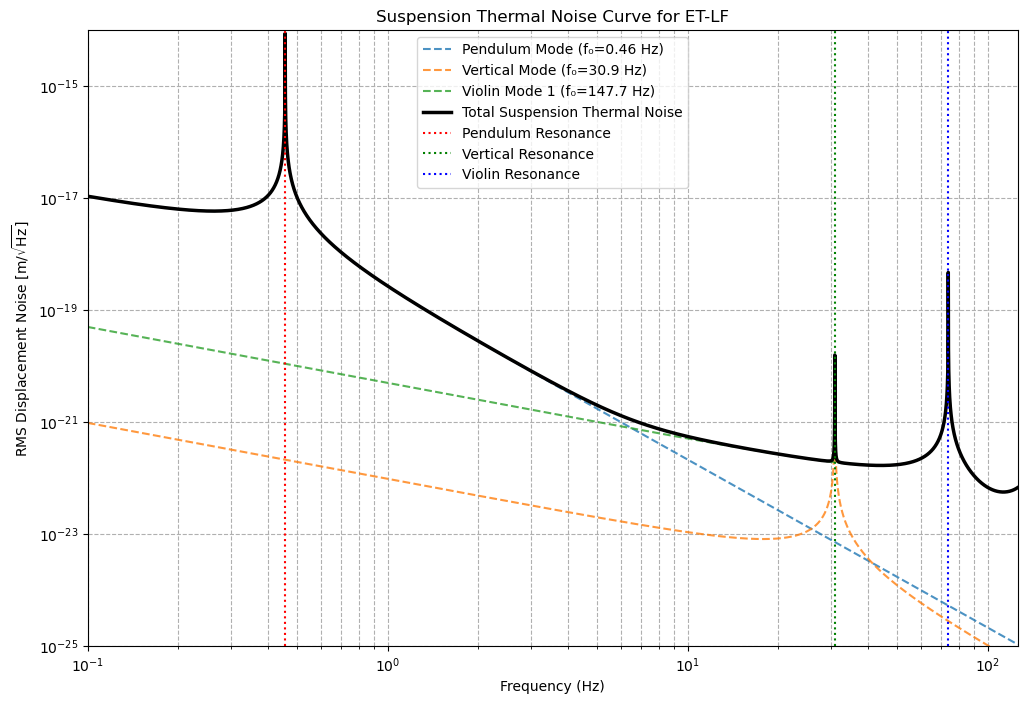

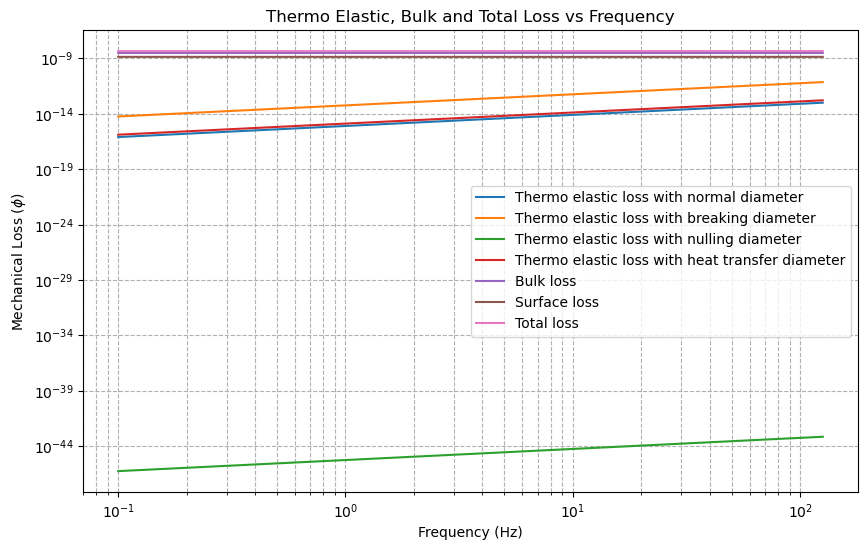

In [3]:
import numpy as np
import matplotlib.pyplot as plt

###################################################################

# Constants and Parameters for ET-LF
k_B = 1.380649e-23
g = 9.81

# ET-LF Parameters
T = 20  # Mirror Temperature (K)
m = 211 # Mirror Mass (kg)
l = 1.2   # Suspension Fiber Length (m)
d = 3.0e-3 # Mirror Suspension Diameter (m)
num_fibers = 4 # Number of suspension fibers
L_arm = 10000 # Arm length (m) for strain conversion

# Material Properties for Silicon at Cryogenic Temperatures
Y = 169e9  # Young's Modulus (Pa) #changing it to 130 decreases the vertical mode
rho = 2330 # Density (kg/m^3)
C = 3.4   # Specific Heat Capacity (J/kg*K) at 20K
alpha = -2.9e-9 # Thermal Expansion Coefficient (1/K) at 20K
beta = -7.9e-6 # d(ln Y)/dT (1/K) at 20 K
Kappa = 4940  # Thermal Conductivity (W/m*K) at 20K
phi_bulk_si = 3e-9 # Bulk loss for silicon at 20K 
phi_bulk_si_matrix=np.ones(20000)*phi_bulk_si
hphi_s = 5e-13 # #product of the mechanical loss of the material surface, φs and the depth ,h for silicon
breaking_stress=.23e9#GPa
T_tension = (m * g) / num_fibers
q_dot=0.5#(W)Total Heat Load
###################################################################


###################################################################



# Loss functions
###################################################################
def phi_thermo(omega, T, Y, rho, C, alpha, sigma_0, beta, tau):
    thermo_factor = (alpha - (sigma_0 * beta / Y))**2
    prefactor = (Y * T) / (rho * C)
    return prefactor * thermo_factor * ((omega * tau) / (1 + (omega * tau)**2))
###################################################################

###################################################################
def phi_surface(hphi_s, d):
    return 8 * hphi_s / d
###################################################################

###################################################################
def power_spectral_density(omega, k_B, T, m, omega_0, phi_total):
    numerator = omega_0**2 * phi_total
    denominator = (omega_0**4 * phi_total**2) + (omega_0**2 - omega**2)**2
    prefactor = (4 * k_B * T) / (m * omega**2) # Using standard off-resonance form
    return prefactor * (numerator / denominator)
##################################################################
# Define frequency range
f_values = np.logspace(-1, 2.1, 20000) # 10 Hz to 150 Hz
omega_values = 2 * np.pi * f_values
###################################################################

#Thermo Elastic Noise for original d
A_fiber = np.pi * (d/ 2)**2
sigma_0 = T_tension / A_fiber
mu = rho * A_fiber
tau=(d**2*C*rho)/(13.55*Kappa)
print("original diameter = ",d*1000,"X10^-3 m")
Thermo_phi_normal_d=phi_thermo(omega_values, T, Y, rho, C, alpha, sigma_0, beta,tau)
print("Thermal loss with original diameter = ",Thermo_phi_normal_d)
###################################################################

#Breaking Stress diameter
breaking_d=2*np.sqrt(T_tension/(np.pi*breaking_stress))
A_fiber_breaking = np.pi * (breaking_d/ 2)**2
sigma_0_breaking = T_tension / A_fiber_breaking
mu_optimal = rho * A_fiber_breaking
breaking_tau=(breaking_d**2*C*rho)/(13.55*Kappa)
print("")
print("Breaking stress diameter = ",breaking_d/1000,"X10^-3 m")
#Thermo Elastic Noise for breaking_d
Thermo_phi_breaking_d=phi_thermo(omega_values, T, Y, rho, C, alpha, sigma_0_breaking, beta,breaking_tau)
print("Thermal loss with breaking diameter = ",Thermo_phi_breaking_d)

###################################################################
#Calculating Optimal diameter for nulling thermo elastic loss
def optimal_d(m,g,beta,alpha,Y):
    return 2*np.sqrt((m*g*beta/4)/(alpha*Y*np.pi))
optimal_diameter=optimal_d(m,g,beta,alpha,Y)

###################################################################
#Thermo elastic nulling from optimal diameter
A_fiber_optimal = np.pi * (optimal_diameter/ 2)**2
sigma_0_optimal = T_tension / A_fiber_optimal
mu_optimal= rho * A_fiber_optimal
print("")
optimal_tau=(optimal_diameter**2*C*rho)/(13.55*Kappa)
print("Thermo Elastic nulling diameter = ",optimal_diameter/1000,"X10^-3 m")
#Thermo Elastic Noise for nulling diameter 
Thermo_phi_nulling_d=phi_thermo(omega_values, T, Y, rho, C, alpha, sigma_0_optimal, beta,optimal_tau)
print("Thermal loss with nulling diameter = ",Thermo_phi_nulling_d)
###################################################################

#diameter based on heat transfer rate(Fourriers Law)
T_high=T
T_low=2
heat_transfer_diameter = np.sqrt((4 * q_dot * l) / (Kappa * np.pi * (T_high - T_low)))
A_fiber_heat_transfer = np.pi * (heat_transfer_diameter/ 2)**2
sigma_0_heat_transfer = T_tension / A_fiber_heat_transfer
mu_heat_transfer= rho * A_fiber_heat_transfer
print("")
#print("Stress from optimal silicone fiber = ",sigma_0_heat_transfer/1000000000,"GPa")
heat_transfer_tau=(heat_transfer_diameter**2*C*rho)/(13.55*Kappa)
print("heat transfer diameter = ",heat_transfer_diameter/1000,"X10^-3 m")
#Thermo Elastic Noise for nulling diameter 
Thermo_phi_heat_transfer_d=phi_thermo(omega_values, T, Y, rho, C, alpha, sigma_0_heat_transfer, beta,heat_transfer_tau)
print("Thermal loss with heat transfer diameter = ",Thermo_phi_heat_transfer_d)


###################################################################
# total loss of the fiber material
phi_fiber_total_undiluted = phi_thermo(omega_values, T, Y, rho, C, alpha, sigma_0, beta, d) + phi_bulk_si + phi_surface(hphi_s, d)
###################################################################

#Resonant Modes
###################################################################
# Pendulum
f0_pendulum = (1 / (2 * np.pi)) * np.sqrt(g / l)
omega0_pendulum = 2 * np.pi * f0_pendulum
I = np.pi * d**4 / 64
D_pendulum=(1/(2*l))*np.sqrt((num_fibers*Y*I)/(m*g))#Dilution
print("")
print("Dilution for pendulum mode = ",D_pendulum)
phi_pendulum = phi_fiber_total_undiluted * D_pendulum
psd_pendulum = power_spectral_density(omega_values, k_B, T, m, omega0_pendulum, phi_pendulum)
###################################################################

###################################################################
# Vertical 
k_vertical = (num_fibers * Y * A_fiber) / l
f0_vertical = (1 / (2 * np.pi)) * np.sqrt(k_vertical / (m/2))#Reduced mass for vertical mode
omega0_vertical = 2 * np.pi * f0_vertical
phi_vertical = phi_fiber_total_undiluted # No dilution (D=1)
psd_vertical = power_spectral_density(omega_values, k_B, T, m, omega0_vertical, phi_vertical)
coupling_factor = L_arm / (2*6371e3)
print("coupling factor = ",coupling_factor)
psd_vertical_coupled = psd_vertical * coupling_factor**2
###################################################################

###################################################################
# Violin
total_psd_violin = np.zeros_like(f_values)
modes_to_sum = range(1,3) # Sum the first 3 modes
violin_mode_freqs = {}
for n in modes_to_sum:
    f0_violin = (n / (2 * l)) * np.sqrt(T_tension / mu)
    omega0_violin = 2 * np.pi * f0_violin
    violin_mode_freqs[n] = f0_violin
    
    dilution_violin = D_pendulum/2 #Half of Pendulum
    phi_violin = phi_fiber_total_undiluted*dilution_violin 
    
    total_psd_violin += power_spectral_density(omega_values, k_B, T, m, omega0_violin, phi_violin)
###################################################################



###################################################################    
# Total Sus Thermal Noise
total_psd = psd_pendulum + psd_vertical_coupled + total_psd_violin

# displacement PSD (m^2/Hz) to strain ASD (1/sqrt(Hz)) for plotting
asd_strain_pendulum = np.sqrt(psd_pendulum) #/ L_arm
asd_strain_vertical = np.sqrt(psd_vertical_coupled) #/ L_arm
asd_strain_violin = np.sqrt(total_psd_violin) #/ L_arm
asd_strain_total = np.sqrt(total_psd) #/ L_arm
###################################################################

###################################################################
# Plotting 
plt.figure(figsize=(12, 8))

#plotting noises
plt.loglog(f_values, asd_strain_pendulum, '--', label=f'Pendulum Mode (f₀={f0_pendulum:.2f} Hz)', alpha=0.8)
plt.loglog(f_values, asd_strain_vertical, '--', label=f'Vertical Mode (f₀={f0_vertical:.1f} Hz)', alpha=0.8)
plt.loglog(f_values, asd_strain_violin, '--', label=f'Violin Mode 1 (f₀={f0_violin:.1f} Hz)', alpha=0.8)

# Plot the combined total noise
plt.loglog(f_values, asd_strain_total, label='Total Suspension Thermal Noise', color='k', linewidth=2.5)
###################################################################

###################################################################
# Add vertical lines for the resonant frequencies
plt.axvline(x=f0_pendulum, color='red', linestyle=':', label=f'Pendulum Resonance')
plt.axvline(x=f0_vertical, color='green', linestyle=':', label=f'Vertical Resonance')
plt.axvline(x=violin_mode_freqs[1], color='blue', linestyle=':', label=f'Violin Resonance')


plt.title('Suspension Thermal Noise Curve for ET-LF')
plt.xlabel('Frequency (Hz)')
plt.ylabel('RMS Displacement Noise [m/$\\sqrt{\\mathrm{Hz}}$]')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.xlim(f_values[0], f_values[-1])
plt.ylim(1e-25, 1e-14)
plt.show()
###################################################################

#Plotting Losses
###################################################################
plt.figure(figsize=(10, 6))
# Plot Thermo Elastic loss
plt.loglog(f_values, Thermo_phi_normal_d , label='Thermo elastic loss with normal diameter')
plt.loglog(f_values, Thermo_phi_breaking_d , label='Thermo elastic loss with breaking diameter')
plt.loglog(f_values, Thermo_phi_nulling_d , label='Thermo elastic loss with nulling diameter')
plt.loglog(f_values, Thermo_phi_heat_transfer_d , label='Thermo elastic loss with heat transfer diameter')
# Plot Bulk loss
plt.loglog(f_values, phi_bulk_si_matrix, label='Bulk loss')
# Plot Surface loss
plt.loglog(f_values, np.ones(20000)*phi_surface(hphi_s, d), label='Surface loss')
# Plot total loss
plt.loglog(f_values, phi_fiber_total_undiluted, label='Total loss')
#titles and labels
plt.title('Thermo Elastic, Bulk and Total Loss vs Frequency')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Mechanical Loss ($\phi$)')
#grid and legend
plt.grid(True, which="both", ls="--")
plt.legend()
# Display the combined plot
plt.show()


In [6]:
import numpy as np

# Assume 'f_values' and 'asd_strain_total' are already calculated and exist in your notebook

# Define the frequency you want to find
target_frequency = 3.0

# 1. Find the index of the frequency in your array that is closest to 3.0
index_at_3hz = np.argmin(np.abs(f_values - target_frequency))

# 2. Use that index to get the corresponding noise value
noise_at_3hz = asd_strain_total[index_at_3hz]

# 3. Get the actual frequency from your array for verification
actual_frequency = f_values[index_at_3hz]

# 4. Print the result in numbers
print(f"--- Noise Value at {target_frequency} Hz ---")
print(f"Closest frequency found in the array: {actual_frequency:.4f} Hz")
print(f"The noise value at this frequency is: {noise_at_3hz:.4e} Strain/sqrt(Hz)")

--- Noise Value at 3.0 Hz ---
Closest frequency found in the array: 2.9996 Hz
The noise value at this frequency is: 8.2446e-21 Strain/sqrt(Hz)
